(mitochondrial_lineage_tracing)=

# Mitochondrial lineage tracing

Call clones in a human colorectal tumor from the somatic mutations in its cells' mitochondrial DNA, and compare its cell types by the clones they share. @Lareau_2020 profiled 3,535 cells of a resected colorectal adenocarcinoma, its epithelial cells and the immune cells that infiltrated it, with mtscATAC-seq, which reads each cell's mitochondrial genome together with its chromatin accessibility. Of the 49,545 variants that the 1,459 singlets with enough mitochondrial reads show, 11 differ between cells by the paper's thresholds, and they place 895 of these cells in 10 clones. Five clones carry 16147C>T, which marks the tumor's epithelial cells, and four of them add a second variant that marks a subclone. Each of the other five clones holds basophil-like, T and NK, and myeloid cells, so these three immune types share clones about one standard deviation more often than shuffled cell types.

Cells that share a somatic mutation in their mitochondrial DNA share an ancestor. A cell holds many copies of its 16,569-base mitochondrial genome, and a mutation in one copy can drift until it fills a large share of them. That share is the mutation's heteroplasmy, and the cell's descendants inherit it, so mitochondrial mutations trace clones in human tissue, where no engineered barcode can be introduced [@Ludwig_2019].

This page is one of four on clonal analysis with `ds.clones`, and here the clones come from mutations that arose naturally in the patient's cells. [Lineage tracing](lineage_tracing.ipynb) follows clones that lentiviral LARRY barcodes mark in mouse hematopoiesis over days 2, 4 and 6, [lineage recorders](lineage_recorders.ipynb) cuts the PEtracer phylogeny of a mouse embryo into clones, and [immune repertoires](immune_repertoires.ipynb) groups T and B cells into clonotypes by their receptor chains. Each page saves its clones in the store as an {term}`artifact`, a result recorded with its inputs and parameters, and the clone summaries of `ds.clones` read the clones of any of them.

## Download the data

[Zenodo record 3977808](https://zenodo.org/records/3977808) holds processed data of the paper under CC BY 4.0. For the colorectal cancer sample, download two outputs of Cell Ranger ATAC: the counts in peaks of the barcodes it called cells, and its metrics for every barcode. Then download six outputs of mgatk, the paper's tool for mitochondrial variants: each cell's reads of A, C, G and T at each mitochondrial position, in one file per base, each cell's mean depth, and the reference sequence. The eight files take 211 MB. Each download is tried up to 4 times, 30 seconds apart, and checked against the MD5 checksum that Zenodo lists for it.

The example uses a temporary directory. Use a project directory instead if you want to keep the downloaded files and the store after closing the notebook.

In [1]:
import hashlib
import shutil
import time
from http.client import HTTPException
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlopen

import pandas as pd

import cytearc
from cytearc.plotting import CellField

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Keep this example's downloads and store together.
work = TemporaryDirectory()
output_dir = Path(work.name)

Started: 2026-11-12T16:22:14.414623Z | Wall time: 1.015 s

In [2]:
# Pin the eight files to the checksums that Zenodo lists, so that a changed
# download cannot alter the example silently.
record = "https://zenodo.org/records/3977808/files/CRC_v12-mtMask_mgatk."
cell_ranger_files = {
    "filtered_peak_bc_matrix.h5": "650f21439dd46d4941b454ccd241f316",
    "singlecell.csv": "bda506977f7d219335bcd1c198e79a79",
}
mgatk_files = {
    "A.txt.gz": "584be3fd63b3d4c4f5135bf3e7e6adad",
    "C.txt.gz": "5bf7ace3e682df978f5d9b2206657663",
    "G.txt.gz": "aae5a90a1e1071862407bd37d932f1df",
    "T.txt.gz": "44ea9fb15dd0676828c1a1da29f37daf",
    "depthTable.txt": "de7672365bfdb069776b469b3fee280a",
    "chrM_refAllele.txt": "07253834698fa1171e55971b715511a8",
}


# Stream a file to disk, retrying a connection that fails or times out, and
# reject a file whose contents differ from the published one.
def download(url: str, path: Path, expected_digest: str, attempts: int = 4) -> None:
    for attempt in range(1, attempts + 1):
        try:
            with urlopen(url, timeout=60) as response, path.open("wb") as target:
                shutil.copyfileobj(response, target)
            break
        except (OSError, HTTPException) as error:
            if attempt == attempts:
                raise RuntimeError(
                    f"Could not download {url} in {attempts} attempts"
                ) from error
            time.sleep(30)
    with path.open("rb") as source:
        actual_digest = hashlib.file_digest(source, "md5").hexdigest()
    if actual_digest != expected_digest:
        raise ValueError(
            f"Checksum mismatch for {path.name}: expected {expected_digest}, "
            f"got {actual_digest}"
        )


# Keep mgatk's six files in a folder of their own, which the import reads.
mgatk_dir = output_dir / "mgatk"
mgatk_dir.mkdir()
paths = {}
for folder, files in ((output_dir, cell_ranger_files), (mgatk_dir, mgatk_files)):
    for name, expected_digest in files.items():
        paths[name] = folder / f"CRC_v12-mtMask_mgatk.{name}"
        download(record + name, paths[name], expected_digest)

# Show the size of each download and their total.
sizes = pd.Series(
    {name: path.stat().st_size / 1_000_000 for name, path in paths.items()},
    name="MB",
)
sizes["Total"] = sizes.sum()
sizes.round(1)

filtered_peak_bc_matrix.h5     18.8
singlecell.csv                 23.2
A.txt.gz                       51.4
C.txt.gz                       51.7
G.txt.gz                       24.2
T.txt.gz                       41.8
depthTable.txt                  0.1
chrM_refAllele.txt              0.1
Total                         211.4
Name: MB, dtype: float64

Started: 2026-11-12T16:22:15.431501Z | Wall time: 210.635 s

## Filter the cells as the paper did

`CrToZarr` writes the peak counts into a store with an `ATAC` assay, one row per barcode that Cell Ranger called a cell. The paper kept the cells with at least 1,000 unique nuclear fragments, at least 40% of them in DNase hypersensitive sites (regions open in many cell types), and a mitochondrial depth of at least 10 reads per position [@Lareau_2020]. Cell Ranger's metrics hold the first two: `passed_filters` counts each barcode's fragments that remain once duplicate, chimeric, unmapped, low-quality and mitochondrial reads are set aside, and `DNase_sensitive_region_fragments` those of them in DNase hypersensitive sites. The depth filter follows once the mitochondrial counts are imported.

`snapshot_cell_selection` saves the passing cells as a cell selection, a frozen list of cells that later steps take as input, so every step analyzes exactly these cells.

In [3]:
# Write the peak counts into a new store and open it.
store_path = output_dir / "crc.zarr"
cytearc.CrToZarr(
    cytearc.CrH5Reader(str(paths["filtered_peak_bc_matrix.h5"])),
    zarr_loc=str(store_path),
).dump()
ds = cytearc.DataStore(str(store_path), default_assay="ATAC")

# Read each cell's unique nuclear fragments, and the share of them in DNase
# hypersensitive sites, from Cell Ranger's per-barcode metrics.
cell_ids = ds.cells.fetch_all("ids")
metrics = pd.read_csv(paths["singlecell.csv"], index_col="barcode").loc[cell_ids]
nuclear_fragments = metrics["passed_filters"]
dnase_share = metrics["DNase_sensitive_region_fragments"] / nuclear_fragments

# Mark the cells that pass both bounds, and freeze them as a cell selection.
passes_qc = (nuclear_fragments >= 1000) & (dnase_share >= 0.4)
ds.cells.insert("passes_qc", passes_qc.to_numpy())
qc_cells = ds.snapshot_cell_selection("passes_qc")

# Count the cells that each bound keeps.
pd.Series(
    {
        "Called by Cell Ranger": len(metrics),
        "At least 1,000 nuclear fragments": int((nuclear_fragments >= 1000).sum()),
        "At least 40% of them in DNase sites": int((dnase_share >= 0.4).sum()),
        "Both": int(passes_qc.sum()),
    },
    name="Cells",
)

Called by Cell Ranger                  3535
At least 1,000 nuclear fragments       2004
At least 40% of them in DNase sites    3533
Both                                   2003
Name: Cells, dtype: int64

Started: 2026-11-12T16:25:46.068489Z | Wall time: 8.623 s

2,003 of the 3,535 cells pass, nearly all of the others for too few fragments.

## Name the cell types

The ATAC recipe, `ds.pipeline.atac`, reduces the peak counts of these cells with latent semantic indexing (LSI), then builds, embeds and clusters their neighbor graph. It returns a {term}`pipeline run <PipelineRun>`, the saved record of these steps, from which the page reads the clusters, the UMAP and the cells that the recipe analyzed as `run["clusters"]`, `run["umap"]` and `run["analysis_cell_selection"]`. The settings are those of the [scATAC-seq analysis of PBMCs](scatac_seq.ipynb): 50 LSI components of the 25,000 most prevalent peaks, and 21 neighbors. To name the clusters, sum the accessibility of the peaks that overlap each gene into a `GeneScores` assay, from gene intervals on the reference of the peaks, hg19 (GRCh37). Two warnings are expected: the peaks leave out the mitochondrial genome, and 35,450 of the 62,446 genes overlap no peak.

In [4]:
# Analyze the cells that pass with the settings of the PBMC analysis, and skip
# ranking marker peaks, which this page does not use.
run = ds.pipeline.atac(
    label="atac",
    cells=qc_cells,
    prevalent_peaks={"top_n": 25000},
    lsi={"dims": 50, "skip_first": True},
    neighbors={"k": 21},
    markers=False,
)
clusters = run["clusters"]

# Download gene intervals for the reference genome of the peaks.
annotations = cytearc.datasets.connect("cytearc_docs").download_dataset(
    "annotations", destination=output_dir
)

# Sum the accessibility of the peaks that overlap each gene.
ds.add_melded_assay(
    from_assay="ATAC",
    external_bed_fn=str(annotations / "human_GRCh37_gencode_v38_gene_body.bed.gz"),
    renormalization=False,
    assay_label="GeneScores",
    assay_type="RNA",
)

Started: 2026-11-12T16:25:54.693280Z | Wall time: 138.873 s

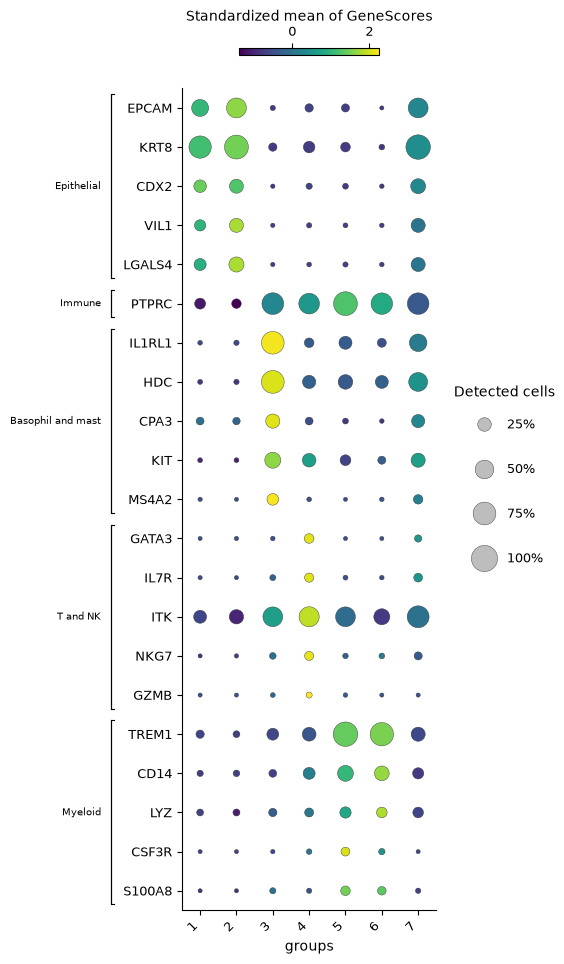

Started: 2026-11-12T16:28:13.568531Z | Wall time: 2.312 s

In [5]:
# Compare the gene scores of cell-type markers across the clusters.
marker_panel = {
    "Epithelial": ["EPCAM", "KRT8", "CDX2", "VIL1", "LGALS4"],
    "Immune": ["PTPRC"],
    "Basophil and mast": ["IL1RL1", "HDC", "CPA3", "KIT", "MS4A2"],
    "T and NK": ["GATA3", "IL7R", "ITK", "NKG7", "GZMB"],
    "Myeloid": ["TREM1", "CD14", "LYZ", "CSF3R", "S100A8"],
}
ds.plots.dotplot(
    features=marker_panel,
    groups=clusters,
    from_assay="GeneScores",
    standardize="feature",
)

Clusters 1 and 2 are epithelial, accessible at EPCAM, the keratin gene KRT8, the intestinal transcription factor CDX2, and the intestinal epithelial genes VIL1 and LGALS4. PTPRC, the gene of the immune cell marker CD45, is accessible in clusters 3 to 6: in cluster 3 with the genes of basophils and mast cells (the paper calls these cells basophil-like), in cluster 4 with the genes of T and NK cells, and in clusters 5 and 6 with the genes of myeloid cells. Cluster 7 is accessible at both the epithelial genes and those of the basophil-like cells.

In [6]:
# Count each cluster's cells and the median of their counts in peaks.
cluster_labels = ds.artifacts.load_values(clusters).to_pandas().rename("cluster")
peak_counts = pd.Series(ds.cells.fetch_all("ATAC_nCounts"), index=cell_ids)
pd.DataFrame(
    {
        "Cells": cluster_labels.value_counts().sort_index(),
        "Median counts in peaks": peak_counts.groupby(cluster_labels).median(),
    }
)

,Cells,Median counts in peaks
cluster,,
1,646,4360.0
2,394,6871.5
3,316,12488.0
4,238,8902.0
5,187,15102.0
6,167,8794.0
7,55,19307.0


Started: 2026-11-12T16:28:15.882495Z | Wall time: 0.041 s

Cluster 7 also holds the most counts in peaks, 19,307 per cell at the median against 4,360 to 15,102 in the others, as droplets with two cells do: its 55 cells are doublets of an epithelial and a basophil-like cell.

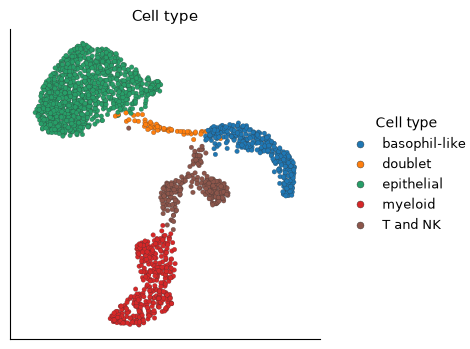

Started: 2026-11-12T16:28:15.925082Z | Wall time: 0.261 s

In [7]:
# Name each cluster by its cell type, and fix the order in which later
# tables list the types.
cell_type_by_cluster = {
    1: "epithelial",
    2: "epithelial",
    3: "basophil-like",
    4: "T and NK",
    5: "myeloid",
    6: "myeloid",
    7: "doublet",
}
type_order = pd.CategoricalDtype(list(dict.fromkeys(cell_type_by_cluster.values())))
cell_types = cluster_labels.map(cell_type_by_cluster).astype(type_order)
cell_types = cell_types.rename("cell type")

# Save each cell's type as a cell column, and name the cells that quality
# control removed "not analyzed".
ds.cells.insert(
    "cell_type",
    cell_types.astype(str).reindex(cell_ids, fill_value="not analyzed"),
    overwrite=True,
)

# Locate the cell types on the UMAP.
ds.plots.embedding(
    layout=run["umap"], color_by=CellField("cell_type", label="Cell type")
)

The doublets bridge the epithelial and the basophil-like cells on the UMAP.

## Import the mitochondrial counts

mgatk counts each cell's reads of each base at each of the 16,569 positions of the mitochondrial genome, on each strand of DNA. `variants.import_counts` reads mgatk's folder and joins each barcode to the store's cell with the same ID. Import the counts for the cells that the ATAC recipe analyzed, so that the variants and clones share the cells of the UMAP. A cell's depth at a position is its reads there, and its allele frequency of a variant is its reads of the variant over that depth, an estimate of the variant's heteroplasmy in the cell. Where a cell has no read at a position, its frequency there is undefined rather than 0.

In [8]:
# Import mgatk's counts for the cells of the ATAC analysis.
counts = ds.variants.import_counts(
    mgatk_dir, cell_selection=run["analysis_cell_selection"]
)

# Check how mgatk's barcodes joined the store's cells.
joined = ds.artifacts.inspect(counts).diagnostics
pd.Series(
    {
        "Barcodes in mgatk's files": joined["fileBarcodes"],
        "Of cells outside the analysis": joined["unselectedBarcodes"],
        "Matching no cell of the store": joined["unmatchedBarcodes"],
        "Analyzed cells with counts": joined["listedCells"],
    },
    name="Barcodes",
)

Barcodes in mgatk's files        3511
Of cells outside the analysis    1508
Matching no cell of the store       0
Analyzed cells with counts       2003
Name: Barcodes, dtype: int64

Started: 2026-11-12T16:28:16.187968Z | Wall time: 19.513 s

All 2,003 analyzed cells have counts, and the other 1,508 barcodes of mgatk's files belong to cells outside the analysis.

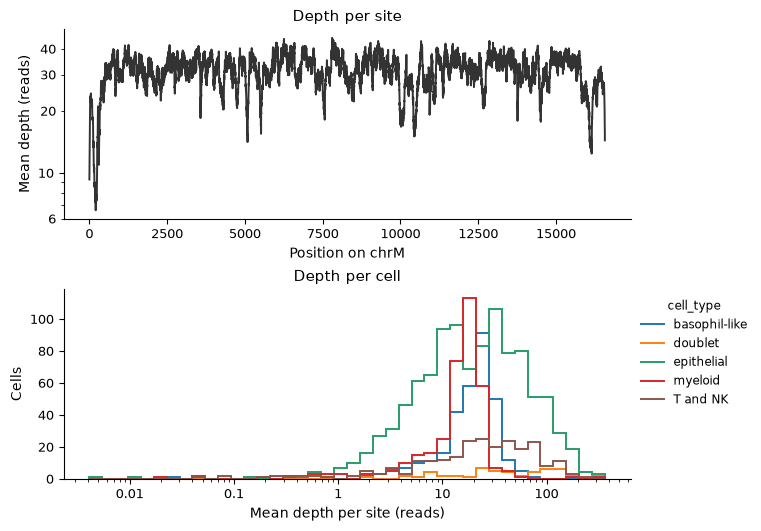

Started: 2026-11-12T16:28:35.702910Z | Wall time: 0.784 s

In [9]:
# Draw the mean depth at each position, and each cell's mean depth by cell type.
ds.plots.variant_depth(counts, group_by="cell_type")

In [10]:
# Count the cells of each type, their median depth, and the number and share
# of them with a mean depth of at least 10 reads.
mean_depth = ds.artifacts.load_values(counts).to_pandas()
depth_by_type = mean_depth.groupby(cell_types.reindex(mean_depth.index), observed=True)
pd.DataFrame(
    {
        "Cells": depth_by_type.size(),
        "Median depth": depth_by_type.median().round(1),
        "Depth of 10 or more": depth_by_type.apply(lambda depth: (depth >= 10).sum()),
        "Share of the cells": depth_by_type.apply(
            lambda depth: (depth >= 10).mean()
        ).round(2),
    }
)

,Cells,Median depth,Depth of 10 or more,Share of the cells
cell type,,,,
epithelial,1040,19.9,727,0.70
basophil-like,316,21.1,271,0.86
T and NK,238,24.2,181,0.76
myeloid,354,16.3,280,0.79
doublet,55,45.3,46,0.84


Started: 2026-11-12T16:28:36.488782Z | Wall time: 0.034 s

Mean depth is similar along most of the mitochondrial genome and falls near both ends of its numbering. Most cells reach the paper's bound of 10 reads per position: 70% of the epithelial cells and 76% to 86% of each immune type. The doublets read the mitochondria of two cells and reach the highest median depth, 45.3 reads per position. Call the cells that reach the bound deep cells. The variant analysis uses the deep singlets, the deep cells outside the doublet cluster.

In [11]:
# Keep the cells with a mean depth of at least 10 reads, and the singlets
# among them.
deep_cells = ds.select_cells(counts, low=10, keep_bounds=True)
deep_singlets = ds.select_cells(
    clusters, include=[1, 2, 3, 4, 5, 6], cell_selection=deep_cells
)

Started: 2026-11-12T16:28:36.524720Z | Wall time: 0.079 s

## Find the informative variants

A variant is a base that differs from the reference at a position, such as `16147C>T`, a T where the reference holds C at position 16,147. Germline variants, which the patient inherited, are carried by every cell, and informative variants differ between cells. `variants.informative` scores each variant with the statistics of mgatk [@Lareau_2020]: the variance-to-mean ratio (VMR) of its allele frequency across cells, high when some cells carry the variant and others do not; its strand correlation, the agreement of its reads on the two strands of DNA across cells, since sequencing errors tend to appear on one strand; and the number of cells in which it is detected confidently, with at least two reads of it on each strand. `preset="atac"` applies the paper's thresholds: a variant detected confidently in at least 5 cells, with a strand correlation of at least 0.65 and a VMR above 0.01. The masks leave out variants that artifacts mimic: `"numt"` those that reads of nuclear copies of mitochondrial DNA (NUMTs) cause, and `"artifact_prone"` every variant at the homopolymers that sequencers misread and at the reference's unknown base.

In [12]:
# Score every variant that the deep singlets show, and select the informative
# ones by the thresholds for mtscATAC-seq.
informative = ds.variants.informative(
    counts,
    cell_selection=deep_singlets,
    preset="atac",
    mask=["numt", "artifact_prone"],
)

# List the informative variants by their pooled allele frequency.
variants = ds.variants.load_informative(informative).variants
selected = variants[variants["informative"]].sort_values("mean", ascending=False)
print(f"{len(selected)} of {len(variants):,} variants are informative")
selected[["mean", "vmr", "strand_correlation", "n_cells_conf_detected"]].round(3)

11 of 49,545 variants are informative


,mean,vmr,strand_correlation,n_cells_conf_detected
variant,,,,
chrM:16147C>T,0.603,0.402,0.913,621
chrM:12889G>A,0.021,0.141,0.875,88
chrM:9728C>T,0.013,0.352,0.922,30
chrM:1227G>A,0.008,0.222,0.969,25
chrM:16093T>C,0.008,0.738,0.994,8
chrM:2285T>C,0.005,0.956,0.926,9
chrM:824T>C,0.005,0.875,0.968,10
chrM:9804G>A,0.003,0.978,0.979,9
chrM:6081G>A,0.003,0.255,0.820,8


Started: 2026-11-12T16:28:36.606275Z | Wall time: 4.159 s

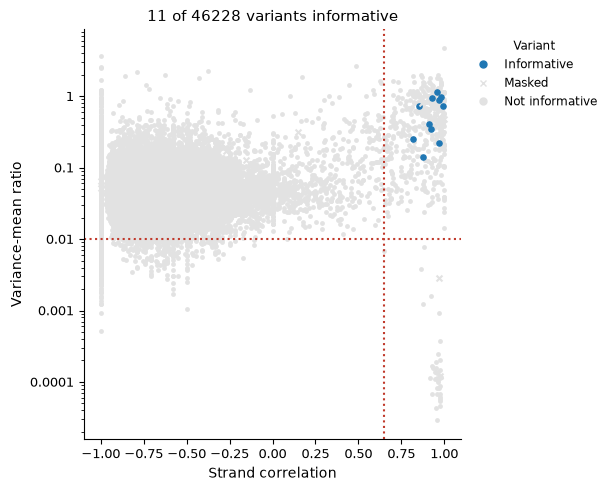

Started: 2026-11-12T16:28:40.767151Z | Wall time: 0.604 s

In [13]:
# Draw each variant's VMR against its strand correlation.
ds.plots.variant_statistics(informative)

Of the 49,545 variants that the deep singlets show, 11 pass. 16147C>T makes up 60% of the reads at its position, and each of the other ten makes up 0.1 to 2.1% of the reads at its own, since each is detected confidently in only 5 to 88 cells. The gray points at the lower right of the plot are germline variants, which every cell carries. The gray points at the upper right pass both dotted lines but are detected confidently in fewer than 5 cells. The plot leaves out the variants without a strand correlation, such as those that a single cell shows, so its title counts fewer variants than the 49,545 printed above.

## See which cells carry each variant

Compute the allele frequencies of the informative variants in every deep cell, the doublets included, and set the cell types beside the frequency of 16147C>T.

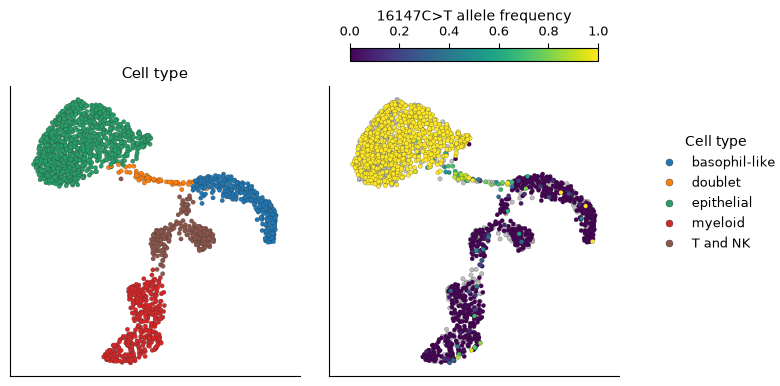

Started: 2026-11-12T16:28:41.373339Z | Wall time: 2.443 s

In [14]:
# Read the counts at the informative variants' positions in the deep cells.
loaded = ds.variants.load_counts(
    counts, sites=selected["position"].tolist(), cell_selection=deep_cells
)

# Divide each cell's reads of each variant by its depth at the position. A
# covered cell without a read of the variant has frequency 0, and a cell that
# was not covered has none.
frequencies = {}
for label, variant in selected.iterrows():
    depth = loaded.depth[loaded.depth["site"] == variant["site"]].set_index("ids")
    reads = loaded.counts[
        (loaded.counts["site"] == variant["site"])
        & (loaded.counts["allele"] == variant["alternative"])
    ].set_index("ids")
    name = label.removeprefix("chrM:")
    frequencies[name] = (
        reads["count"].reindex(depth.index, fill_value=0) / depth["depth"]
    )
frequencies = pd.DataFrame(frequencies)

# Save each frequency as a cell column, and set the cell types beside the
# frequency of 16147C>T, the most frequent informative variant.
for name in frequencies:
    ds.cells.insert(name, frequencies[name].reindex(cell_ids), overwrite=True)
ds.plots.embedding(
    layout=run["umap"],
    color_by=[
        CellField("cell_type", label="Cell type"),
        CellField("16147C>T", kind="continuous", label="16147C>T allele frequency"),
    ],
    n_columns=2,
    sort_values=True,
)

16147C>T reaches a frequency near 1 across the epithelial cells and stays near 0 in the immune cells, so it marks the tumor. The doublets on the bridge carry it at intermediate frequencies, as droplets that mix the mitochondria of a tumor cell and a basophil-like cell would. Gray cells have no frequency: they fell below the depth bound, or no read covered the position.

The other ten variants each mark fewer cells. Draw their frequencies, and count the deep cells of each type in which each variant is detected confidently.

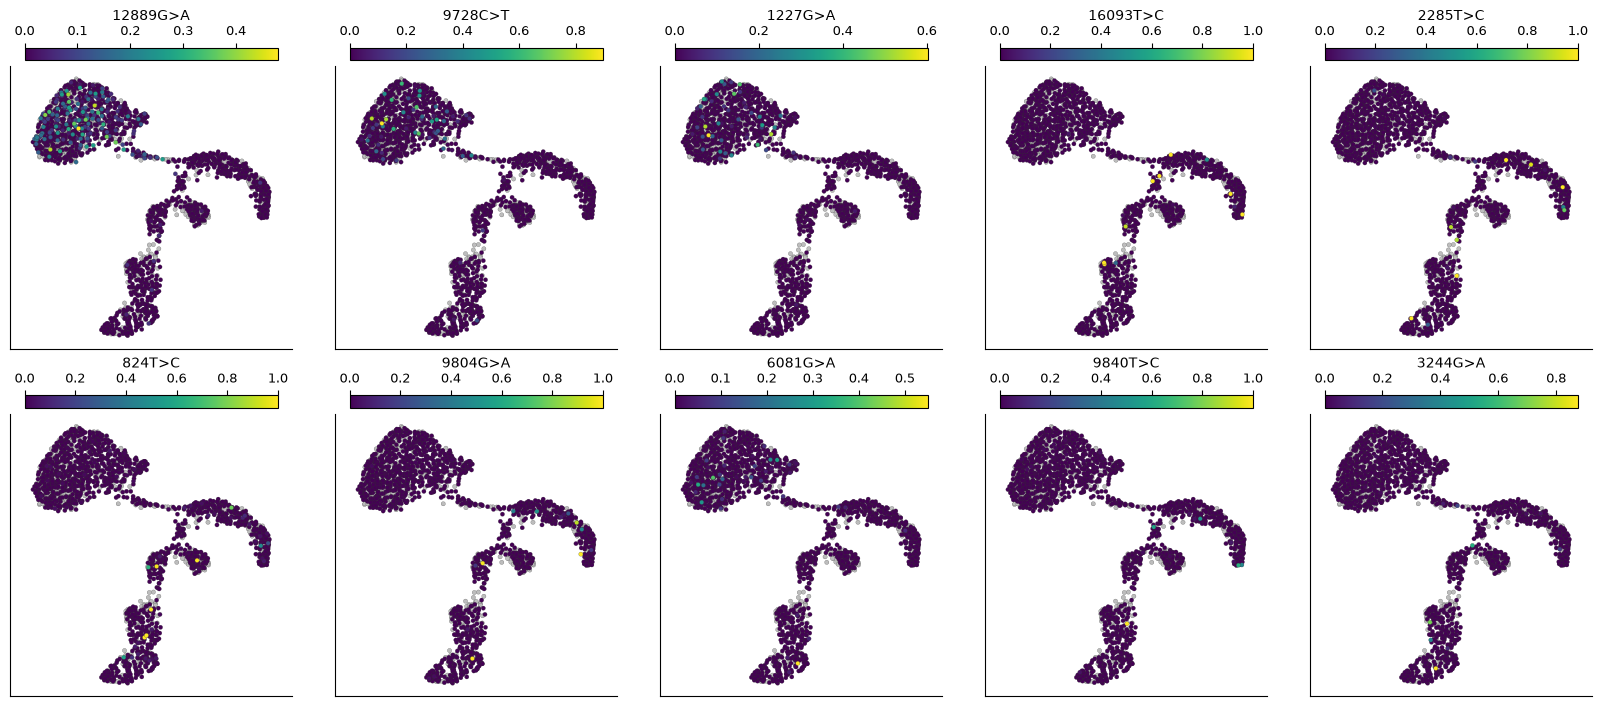

Started: 2026-11-12T16:28:43.818444Z | Wall time: 1.675 s

In [15]:
# Draw the frequencies of the other informative variants.
ds.plots.embedding(
    layout=run["umap"],
    color_by=[name for name in frequencies if name != "16147C>T"],
    n_columns=5,
    sort_values=True,
)

In [16]:
# Count the deep cells of each type with at least two reads of each variant on
# each strand.
confident = {}
for label, variant in selected.iterrows():
    reads = loaded.counts[
        (loaded.counts["site"] == variant["site"])
        & (loaded.counts["allele"] == variant["alternative"])
    ]
    carriers = reads.loc[(reads["forward"] >= 2) & (reads["reverse"] >= 2), "ids"]
    confident[label.removeprefix("chrM:")] = (
        cell_types.reindex(carriers).value_counts(sort=False)
    )
pd.DataFrame(confident).T

cell type,epithelial,basophil-like,T and NK,myeloid,doublet
16147C>T,600,5,9,7,38
12889G>A,85,0,2,1,11
9728C>T,29,0,0,1,3
1227G>A,25,0,0,0,1
16093T>C,0,3,3,2,0
2285T>C,0,5,2,2,1
824T>C,0,3,3,4,0
9804G>A,0,6,2,1,0
6081G>A,7,0,0,1,2
9840T>C,0,3,1,1,0


Started: 2026-11-12T16:28:45.495491Z | Wall time: 0.042 s

16147C>T is detected confidently in 600 of the 727 deep epithelial cells, in 38 of the 46 deep doublets, and in 5 to 9 cells of each immune type. Four variants mark parts of the epithelial cells, subclones of the tumor: 12889G>A is detected confidently in 85 epithelial cells, 9728C>T in 29, 1227G>A in 25 and 6081G>A in 7. Each of the six others is detected confidently in only 5 to 10 deep singlets, all of them immune cells and spread over all three immune types, so each most likely arose in a hematopoietic progenitor of these lineages.

## Call clones

`variants.frequency_clones` groups the cells whose variants agree, as Signac's `FindClonotypes` does [@Stuart_2021]. It finds each cell's neighborhood of 10 cells by the cosine similarity of the square roots of their allele frequencies, joins the cells whose neighborhoods overlap into a graph, and partitions the graph with the Leiden algorithm [@Traag_2019]. The cosine compares the pattern of a cell's frequencies across the variants, not their level. Cells that show none of the informative variants get no clone. The resolution of the Leiden algorithm sets how finely it splits the graph; this page uses 0.75, below the default of 1, and checks that choice once the clones are read.

In [17]:
# Call clones from the informative variants of the deep singlets.
clones = ds.variants.frequency_clones(informative, resolution=0.75)

# Count the cells that the clones hold and those they leave out.
clone_diagnostics = ds.artifacts.inspect(clones).diagnostics
pd.Series(
    {
        "Deep singlets": clone_diagnostics["cellsScored"],
        "With a clone": clone_diagnostics["cellsWithClone"],
        "Showing no informative variant": clone_diagnostics["cellsWithoutAlternative"],
    },
    name="Cells",
)

Deep singlets                     1459
With a clone                       895
Showing no informative variant     564
Name: Cells, dtype: int64

Started: 2026-11-12T16:28:45.538943Z | Wall time: 4.478 s

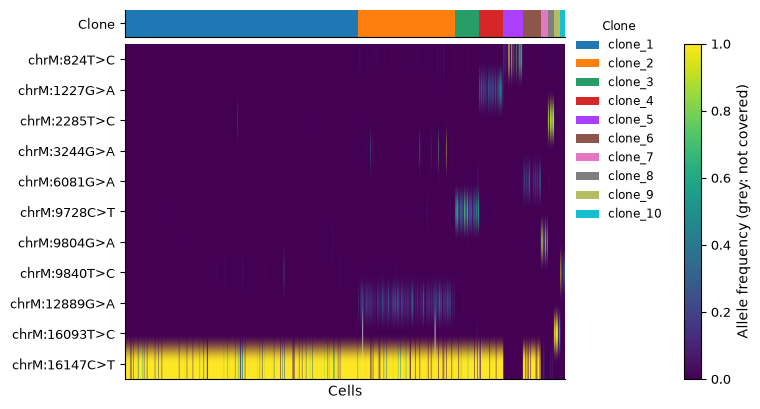

Started: 2026-11-12T16:28:50.018285Z | Wall time: 2.267 s

In [18]:
# Draw each cell's allele frequencies, ordered by clone.
ds.plots.allele_frequencies(informative, clones=clones)

In [19]:
# Name the variants that each clone's cells carry at a mean frequency of at
# least 10%.
def clone_variants(clone_ref):
    clone_of = ds.clones.load_clones(clone_ref).cells["clone"]
    means = frequencies.groupby(clone_of, observed=True).mean()
    return means.apply(lambda clone: ", ".join(clone.index[clone >= 0.1]), axis=1)


# Count each clone's cells of each type beside its variants.
clone_cells = ds.clones.load_clones(clones).cells
composition = pd.crosstab(clone_cells["clone"], cell_types.reindex(clone_cells.index))
composition.insert(0, "variants", clone_variants(clones))
composition

cell type,variants,epithelial,basophil-like,T and NK,myeloid
clone,,,,,
clone_1,16147C>T,430,12,12,20
clone_2,"16147C>T, 12889G>A",174,5,8,10
clone_3,"16147C>T, 9728C>T",45,0,1,3
clone_4,"16147C>T, 1227G>A",45,0,3,1
clone_5,824T>C,0,14,13,13
clone_6,"16147C>T, 6081G>A",29,2,1,4
clone_7,9804G>A,0,8,2,4
clone_8,2285T>C,0,6,3,4
clone_9,16093T>C,0,5,5,3


Started: 2026-11-12T16:28:52.287422Z | Wall time: 0.080 s

Of the 1,459 deep singlets, 895 get a clone, and the other 564 show none of the informative variants. Clones are numbered by size. Five clones carry 16147C>T: clone_1 carries it alone, and clones 2, 3, 4 and 6 add 12889G>A, 9728C>T, 1227G>A and 6081G>A, the tumor's subclones. The other five clones each carry one immune variant and hold immune cells of all three types. Total each type's cells in the tumor clones and in the immune clones.

In [20]:
# Total each type's cells in the tumor clones, those that carry 16147C>T, and
# in the immune clones.
clone_kind = (
    composition["variants"]
    .str.contains("16147C>T")
    .map({True: "tumor", False: "immune"})
    .rename("clones")
)
totals = composition.drop(columns="variants").groupby(clone_kind, sort=False).sum()
totals["all immune"] = totals[["basophil-like", "T and NK", "myeloid"]].sum(axis=1)
totals

cell type,epithelial,basophil-like,T and NK,myeloid,all immune
clones,,,,,
tumor,723,19,25,38,82
immune,0,38,27,25,90


Started: 2026-11-12T16:28:52.368578Z | Wall time: 0.011 s

The tumor clones hold all 723 epithelial cells with a clone, and also 82 immune cells, nearly as many as the 90 in the immune clones, while 16147C>T is detected confidently in only 5 to 9 deep cells of each immune type. Because the cosine ignores the level of a frequency, a single read of 16147C>T in an immune cell that shows no other informative variant gives the cell the pattern of clone_1. No clone carries 3244G>A, which is detected confidently in 5 cells, and the heatmap shows a few of its carriers in clone_2: a clone of fewer cells than a neighborhood can join the clone its cells resemble most, and a smaller `n_neighbors` keeps such small clones apart.

To check the resolution, call clones at the default of 1 as well, and count the clones whose cells carry 16147C>T alone.

In [21]:
# Call clones at the default resolution of 1 as well, and count the clones of
# each resolution and those whose cells carry 16147C>T alone.
rows = {}
for resolution, clones_at_resolution in (
    (1.0, ds.variants.frequency_clones(informative)),
    (0.75, clones),
):
    names = clone_variants(clones_at_resolution)
    rows[resolution] = {
        "Clones": len(names),
        "Carrying 16147C>T alone": int((names == "16147C>T").sum()),
    }
pd.DataFrame(rows).T.rename_axis("Resolution")

,Clones,Carrying 16147C>T alone
Resolution,,
1.00,11,2
0.75,10,1


Started: 2026-11-12T16:28:52.380982Z | Wall time: 2.351 s

At the default resolution of 1, the Leiden algorithm calls 11 clones, and two of them carry 16147C>T alone, a split that no variant supports. At 0.75, one clone carries 16147C>T alone, and each of the 10 clones carries a combination of variants of its own, so this page keeps 0.75. With other data, compare resolutions in the same way: a resolution set too high splits cells that carry the same variants into several clones, and one set too low merges clones that carry different variants.

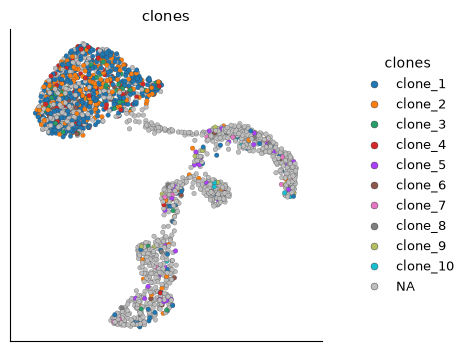

Started: 2026-11-12T16:28:54.733713Z | Wall time: 0.253 s

In [22]:
# Locate the clones on the UMAP.
ds.plots.embedding(layout=run["umap"], color_by=clones)

The subclones mix across the epithelial cells on the UMAP, so their chromatin differs less than that of the cell types. The tumor-clone colors among the immune cells mark the 82 immune cells that the tumor clones hold.

## Compare the cell types by their clones

Cell types that share clones descend from common ancestors. `clones.coupling` measures how much each pair of cell types shares clones with CoSpar's default measure [@Wang_2022], the cosine over the clones of each type's share of each clone. It measures the coupling again on cell types shuffled among the cells with a clone, which keeps each clone's size and each type's size, and reports each pair's z-score: the coupling's distance from the mean of the shuffles, in their standard deviations, positive when a pair shares clones more often than chance.

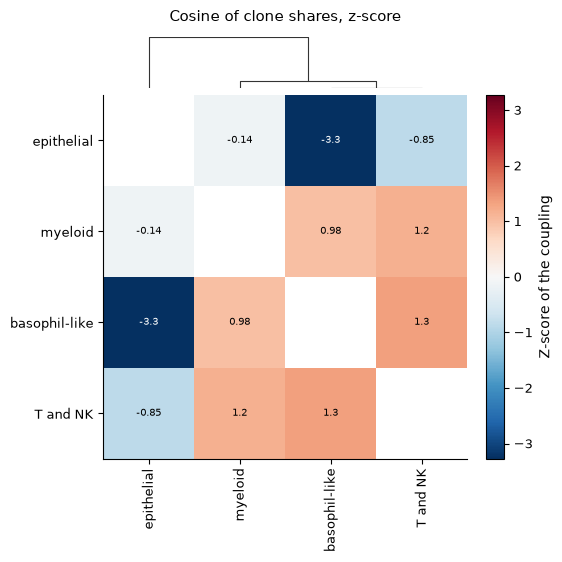

Started: 2026-11-12T16:28:54.988841Z | Wall time: 3.267 s

In [23]:
# Measure how much each pair of cell types shares clones, against shuffled
# cell-type labels, and draw the z-scores.
coupling = ds.clones.coupling(clones, group_by="cell_type")
ds.plots.clone_coupling(coupling, value="z_score")

In [24]:
# Set each pair's coupling beside its mean over the shuffled labels.
pairs = coupling.pairs.set_index(["group_1", "group_2"])
pairs[["coupling", "null_mean", "z_score"]].sort_values("z_score").round(2)

coupling  null_mean  z_score
group_1       group_2                                 
basophil-like epithelial      0.18       0.68    -3.27
epithelial    T and NK        0.54       0.66    -0.85
              myeloid         0.68       0.71    -0.14
basophil-like myeloid         0.74       0.59     0.98
myeloid       T and NK        0.75       0.58     1.17
basophil-like T and NK        0.78       0.58     1.35

Started: 2026-11-12T16:28:58.257671Z | Wall time: 0.011 s

The three immune types couple at 0.74 to 0.78, above their shuffled means of 0.58 and 0.59, with z-scores of 0.98 to 1.35, about one standard deviation above chance, because each of the five immune clones holds cells of all three types. The epithelial cells share clones with the basophil-like cells far less often than chance, at 0.18 against 0.68, a z-score of -3.27, because the tumor clones hold 19 basophil-like cells and the immune clones 38. With the T and NK cells, at 0.54 against 0.66, and with the myeloid cells, at 0.68 against 0.71, the epithelial cells stay within one standard deviation of chance, at z-scores of -0.85 and -0.14, because the tumor clones hold about as many T and NK cells as the immune clones, 25 against 27, and more myeloid cells, 38 against 25.

The raw coupling of the epithelial and myeloid cells nearly matches that of the immune pairs, and only the comparison with the shuffled labels separates them, so this page draws the z-score. The [lineage tracing](lineage_tracing.ipynb) page draws the raw coupling instead: most of its clones commit to a single fate, which puts most pairs below their shuffled mean, and the coupling itself ranks them.

## Next steps

- With several samples or donors, pass `within="donor"` to `variants.frequency_clones`, so that no clone joins the cells of two people.
- For MAESTER and other RNA libraries, select variants with `preset="rna"`, which tests depth and base quality instead of strands.
- Every clone summary, from diversity to fate bias, takes these clones, as the [clones API reference](/api/clones.html) describes. The [variants API reference](/api/variants.html) covers the other formats that `variants.import_counts` reads and the genotypes of targeted sites, from GoT, GIFT, Tapestri and DAb-seq.